# Prompt-to-ASCII
This notebook allows you to test and tweak the ASCII rendering pipeline on sample images before connecting it to diffusion models (SDXL).

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import sys
sys.path.insert(0, '/content/drive/MyDrive')

In [6]:
from customRenderer import AsciiRenderer
print('✅ AsciiRenderer ready')

✅ AsciiRenderer ready


In [7]:
import subprocess, sys, importlib

def pip(*pkgs):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *pkgs])

pip('pillow')
pip('diffusers>=0.27.0', 'transformers>=4.40.0', 'accelerate>=0.29.0', 'safetensors')

if importlib.util.find_spec('torch') is None:
    pip('torch', 'torchvision',
        '--index-url', 'https://download.pytorch.org/whl/cpu')

print('All dependencies ready.')


All dependencies ready.


In [8]:
import torch
from diffusers import StableDiffusionXLPipeline, DPMSolverMultistepScheduler

if torch.cuda.is_available():
    DEVICE, DTYPE = 'cuda', torch.float16
    print('GPU:', torch.cuda.get_device_name(0))
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE, DTYPE = 'mps', torch.float16
    print('Apple Silicon MPS')
else:
    DEVICE, DTYPE = 'cpu', torch.float32
    print('CPU — generation will be slow (~5-15 min per image)')

MODEL_ID = 'stabilityai/stable-diffusion-xl-base-1.0'
print('Loading', MODEL_ID, '...')

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True,
    variant='fp16' if DTYPE == torch.float16 else None,
)

pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config, use_karras_sigmas=True)

if DEVICE == 'cuda':
    try:
        pipe.enable_xformers_memory_efficient_attention()
    except Exception:
        pass
    try:
        pipe.enable_vae_slicing()
    except Exception:
        pass
    try:
        pipe.vae.enable_slicing()
    except Exception:
        pass
    pipe = pipe.to(DEVICE)
elif DEVICE == 'mps':
    pipe = pipe.to(DEVICE)
else:
    try:
        pipe.enable_sequential_cpu_offload()
    except Exception:
        pipe = pipe.to(DEVICE)

print('Model loaded and ready.')


GPU: Tesla T4
Loading stabilityai/stable-diffusion-xl-base-1.0 ...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Model loaded and ready.


In [ ]:
import sys, os, re, time
from pathlib import Path
from PIL import Image

PROMPT = 'A beautiful desert night where you can see small peaks of sand and a night with moon'
NEGATIVE_PROMPT = 'blurry, low quality, watermark, text, oversaturated, cartoon'

NUM_STEPS       = 30      # 20-40 recommended
GUIDANCE_SCALE  = 7.5
IMAGE_WIDTH     = 1024
IMAGE_HEIGHT    = 1024
SEED            = None    # set an int e.g. 42 for reproducible results

ASCII_WIDTH      = 160
ASPECT_RATIO     = 0.50
PALETTE          = 'dots'  # 'dots' | 'clean' | 'detailed' | 'pixel'
FONT_SIZE_HTML   = 9
FONT_SIZE_MOTION = 10
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

NB_DIR = Path(os.getcwd())
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))
from customRenderer import AsciiRenderer

OUTPUT_DIR = NB_DIR / 'output'
OUTPUT_DIR.mkdir(exist_ok=True)

# 1. Generate with SDXL
print(f'Generating: {PROMPT!r}')
t0 = time.time()
generator = (torch.Generator(device=DEVICE).manual_seed(SEED)
             if SEED is not None else None)
result = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    num_inference_steps=NUM_STEPS,
    guidance_scale=GUIDANCE_SCALE,
    width=IMAGE_WIDTH,
    height=IMAGE_HEIGHT,
    generator=generator,
)
generated_img = result.images[0]
print(f'Done in {time.time()-t0:.1f}s')

slug = re.sub(r'[^a-z0-9]+', '_', PROMPT[:40].lower()).strip('_')
raw_img_path = OUTPUT_DIR / f'{slug}_raw.png'
generated_img.save(raw_img_path)
print(f'Saved raw image: {raw_img_path}')

# 2. ASCII render
print('Rendering ASCII...')
renderer = AsciiRenderer(
    width=ASCII_WIDTH, aspect_ratio=ASPECT_RATIO, palette=PALETTE,
    contrast=1.35, saturation=1.4, brightness=1.0, edge_detection=False)

color_html_path = OUTPUT_DIR / f'{slug}_color.html'
renderer.render_to_html(generated_img, output_file=color_html_path, font_size=FONT_SIZE_HTML)
print(f'Color HTML  -> {color_html_path}')

motion_html_path = OUTPUT_DIR / f'{slug}_motion.html'
renderer.render_motion_html(generated_img, output_file=motion_html_path, font_size=FONT_SIZE_MOTION)
print(f'Motion HTML -> {motion_html_path}')

print('Done!')


Generating: 'A beautiful desert night where you can see small peaks of sand and a night with moon'


  0%|          | 0/30 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Done in 30.9s
Saved raw image: /content/output/a_beautiful_desert_night_where_you_can_s_raw.png
Rendering ASCII...
Color HTML  -> /content/output/a_beautiful_desert_night_where_you_can_s_color.html
Motion HTML -> /content/output/a_beautiful_desert_night_where_you_can_s_motion.html
Done!


In [ ]:
import shutil
shutil.copy(
    '/content/output/a_beautiful_desert_night_where_you_can_s_color.html',
    '/content/drive/MyDrive/motion.html'
)
shutil.copy(
    '/content/output/a_beautiful_desert_night_where_you_can_s_motion.html',
    '/content/drive/MyDrive/color.html'
)
print('✅ Files copied to Google Drive root')

✅ Files copied to Google Drive root


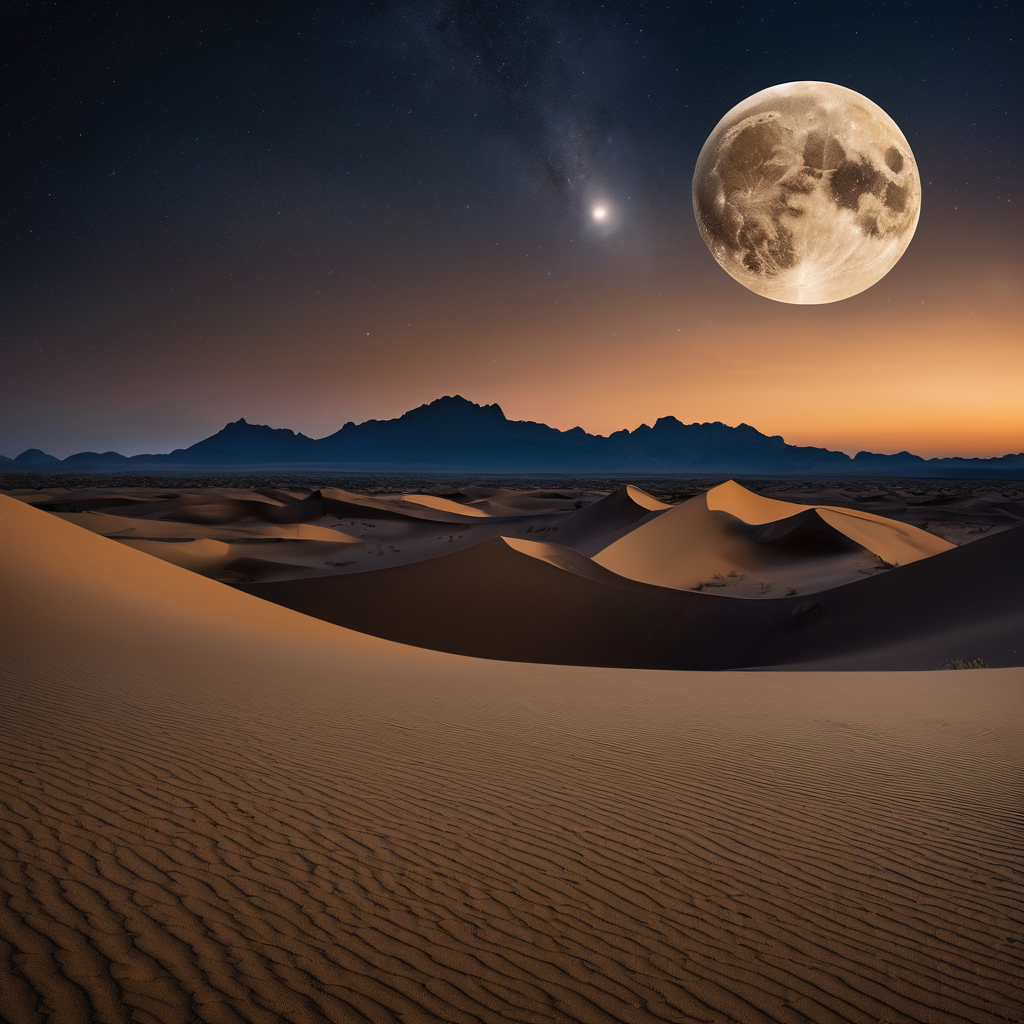

In [19]:
from IPython.display import display
from PIL import Image

img = Image.open("/content/output/a_beautiful_desert_night_where_you_can_s_raw.png")
display(img)

In [ ]:
from IPython.display import display, HTML, Image as IPyImage

print(f'Prompt: {PROMPT}')
display(IPyImage(filename=str(raw_img_path), width=512))
display(HTML(
    '<div style="font-family:monospace;line-height:2;margin-top:8px">'
    '<b>Outputs:</b><br>'
    f'<a href="{color_html_path}" target="_blank">Color HTML (static)</a><br>'
    f'<a href="{motion_html_path}" target="_blank">Motion HTML (animated)</a>'
    '</div>'
))
